# Will This Visitor Buy? — Purchase Intention Prediction

**Machine Learning Final Project**

This notebook follows the project brief: problem framing, data understanding, EDA, preprocessing in a scikit-learn Pipeline, baseline + at least three algorithms, cross-validation and tuning, untouched test evaluation, error analysis, and saving the final pipeline for the Streamlit app.

> Run from top to bottom. All reported metrics must come from this notebook's actual run.

## 1. Problem framing

An e-commerce store wants to estimate whether a browsing session will end in a purchase.

- **Decision supported:** whether to show a coupon, show a chat assistant, or take no action.
- **Target:** `Revenue` (True = purchase, False = no purchase).
- **Main metric:** ROC-AUC to assess ranking quality; also report precision, recall, F1, and the confusion matrix because the classes are imbalanced.
- **Important limitation:** this is a decision-support prototype, not proof that a coupon or chat assistant will cause extra sales.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay
)
from scipy.stats import randint
import joblib
import os

## 2. Load the UCI dataset

In [2]:
# UCI dataset ID 468: Online Shoppers Purchasing Intention
dataset = fetch_ucirepo(id=468)

X = dataset.data.features.copy()
y = dataset.data.targets.copy()

# Make the target a one-dimensional boolean/0-1 series.
if isinstance(y, pd.DataFrame):
    y = y.iloc[:, 0]
y = y.astype(str).str.strip().str.lower().map({"true": 1, "false": 0, "1": 1, "0": 0})

data = X.copy()
data["Revenue"] = y
data = data.dropna(subset=["Revenue"]).reset_index(drop=True)
data["Revenue"] = data["Revenue"].astype(int)

print("Dataset shape:", data.shape)
display(data.head())

Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,0


In [3]:
print("Column types:")
display(data.dtypes.to_frame("dtype"))
print("\\nMissing values:")
display(data.isna().sum().sort_values(ascending=False).to_frame("missing"))
print("\\nTarget distribution:")
display(data["Revenue"].value_counts().rename(index={0: "No purchase", 1: "Purchase"}))
print("\\nTarget percentages:")
display((data["Revenue"].value_counts(normalize=True) * 100).round(2))

Column types:


,dtype
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


\nMissing values:


,missing
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


\nTarget distribution:


Revenue
No purchase    10422
Purchase        1908
Name: count, dtype: int64

\nTarget percentages:


Revenue
0    84.53
1    15.47
Name: proportion, dtype: float64

## 3. Exploratory Data Analysis (EDA)

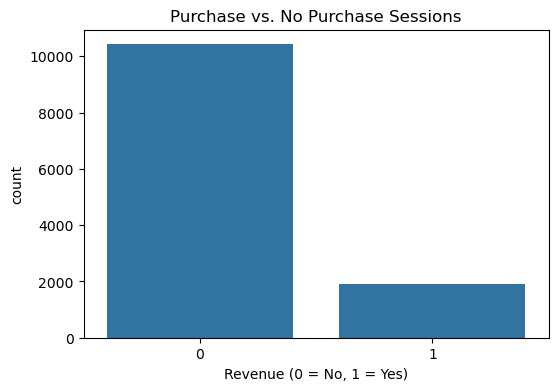

In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(data=data, x="Revenue")
plt.title("Purchase vs. No Purchase Sessions")
plt.xlabel("Revenue (0 = No, 1 = Yes)")
plt.show()

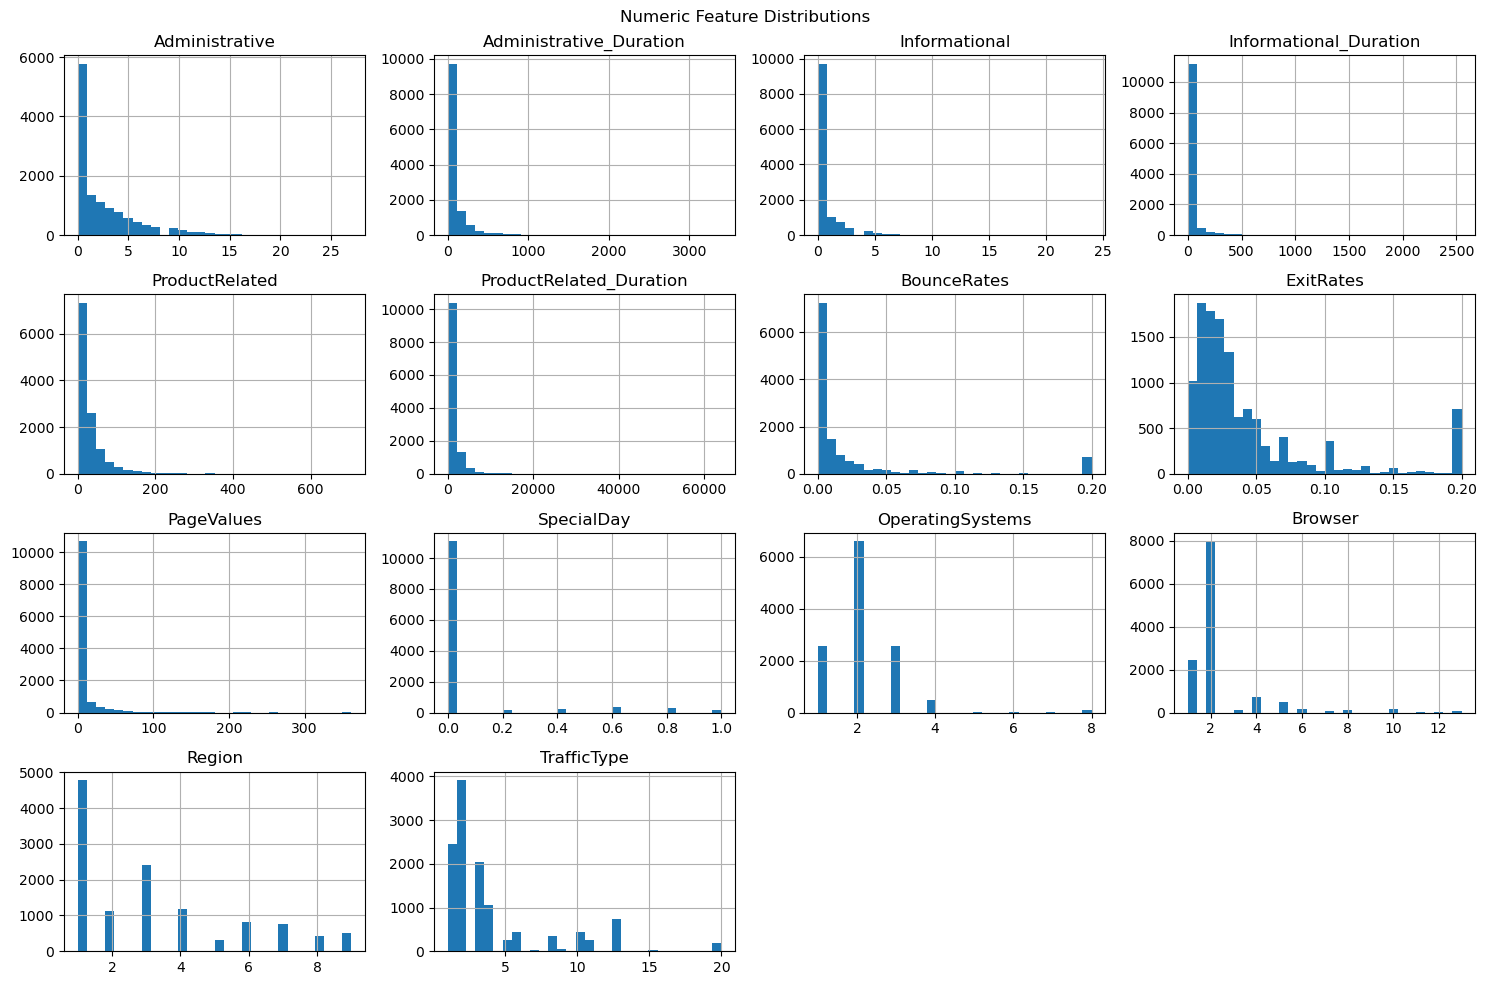

In [5]:
numeric_cols = data.select_dtypes(include=np.number).columns.drop("Revenue", errors="ignore")
data[numeric_cols].hist(figsize=(15, 10), bins=30)
plt.suptitle("Numeric Feature Distributions")
plt.tight_layout()
plt.show()

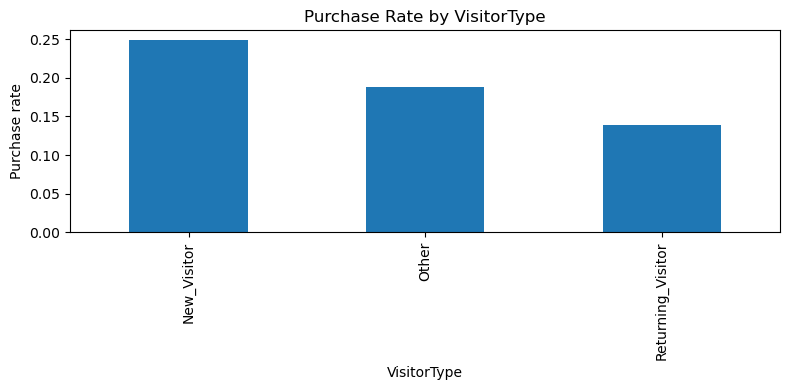

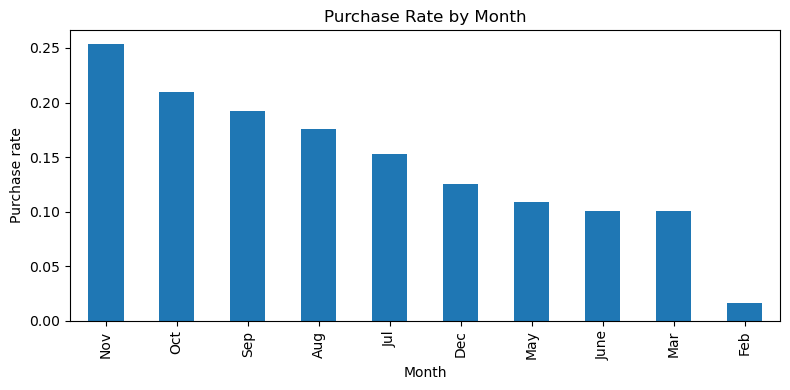

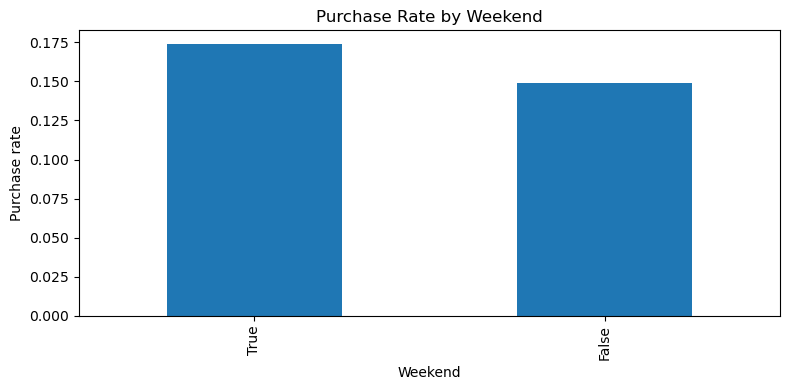

In [6]:
for col in ["VisitorType", "Month", "Weekend"]:
    if col in data.columns:
        rates = data.groupby(col, dropna=False)["Revenue"].mean().sort_values(ascending=False)
        plt.figure(figsize=(8, 4))
        rates.plot(kind="bar")
        plt.title(f"Purchase Rate by {col}")
        plt.ylabel("Purchase rate")
        plt.tight_layout()
        plt.show()

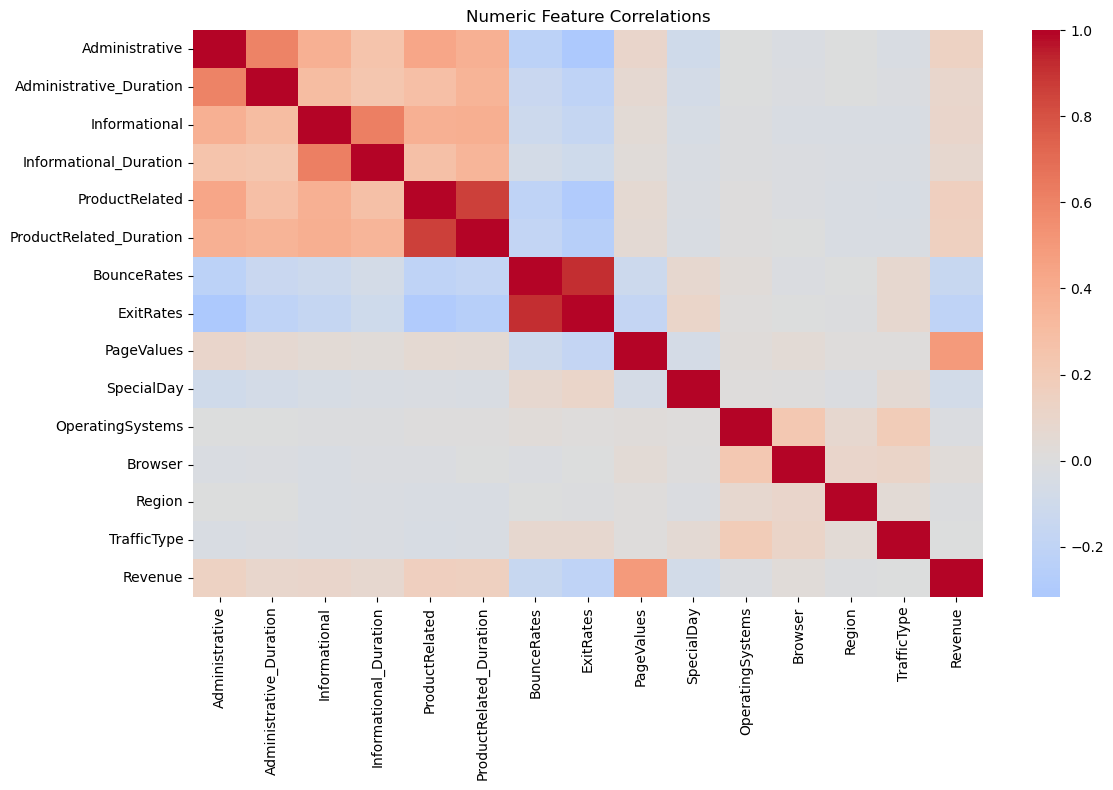

In [7]:
corr = data.select_dtypes(include=np.number).corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Numeric Feature Correlations")
plt.tight_layout()
plt.show()

### EDA insights — complete after running the charts

Write 3–5 observations based on the actual charts and numbers. Do not copy assumptions. Suggested questions:

1. Target Imbalance: Approximately 84.53% of sessions did not result in a purchase, while only 15.47% ended in a purchase. This indicates an imbalanced dataset.

2. Visitor Type: "New Visitors" have the highest purchase rate at approximately 24.5%, followed by the "Other" category, and then "Returning Visitors" at about 12.5%.

3. Monthly Purchase Rate: November shows the highest purchase rate, while February shows the lowest.

4. Weekend Effect: According to the chart, the purchase rate during weekends is slightly higher than on weekdays, though the difference is not significant.

5. Feature Distributions and Correlations: Most variables related to the number of pages visited and browsing duration contain many small values ​​or zeros. Furthermore, the heatmap reveals a notable positive correlation between "PageValues" and "Revenue," and a negative correlation between "BounceRates" and "Revenue."

## 4. Prepare features and split the data

In [8]:
X = data.drop(columns=["Revenue"])
y = data["Revenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Train: (9864, 17)  Test: (2466, 17)
Numeric features: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
Categorical features: ['Month', 'VisitorType', 'Weekend']


## 5. Preprocessing pipeline

All imputing, scaling, and encoding are fitted only on training folds through the Pipeline. This prevents data leakage from the test set.

In [9]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

## 6. Baseline and three different algorithms

In [10]:
models = {
    "Dummy baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=250, random_state=42, class_weight="balanced_subsample", n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=250, random_state=42, class_weight="balanced", n_jobs=-1
    )
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    if hasattr(pipe, "predict_proba"):
        prob = pipe.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, prob)
    else:
        auc = np.nan
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": auc
    })

results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False)
display(results_df)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
3,Random Forest,0.897810,0.746212,0.515707,0.609907,0.921482
4,Extra Trees,0.889700,0.766990,0.413613,0.537415,0.905874
1,Logistic Regression,0.849959,0.510714,0.748691,0.607219,0.896200
2,Decision Tree,0.854420,0.532033,0.500000,0.515520,0.709693
0,Dummy baseline,0.845093,0.000000,0.000000,0.000000,0.500000


## 7. Hyperparameter tuning

Tune the Random Forest using cross-validation on the training set only. The test set remains untouched until final evaluation.

In [11]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=42, class_weight="balanced_subsample", n_jobs=-1
    ))
])

param_distributions = {
    "model__n_estimators": randint(150, 401),
    "model__max_depth": [None, 8, 12, 16, 20,  None],
    "model__min_samples_split": randint(2, 12),
    "model__min_samples_leaf": randint(1, 6),
    "model__max_features": ["sqrt", "log2", 0.7]
}

search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)
search.fit(X_train, y_train)

print("Best CV ROC-AUC:", search.best_score_)
print("Best parameters:", search.best_params_)
best_model = search.best_estimator_

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best CV ROC-AUC: 0.9330569624728104
Best parameters: {'model__max_depth': 12, 'model__max_features': 0.7, 'model__min_samples_leaf': 5, 'model__min_samples_split': 5, 'model__n_estimators': 253}


## 8. Final evaluation on the untouched test set

In [12]:
test_prob = best_model.predict_proba(X_test)[:, 1]
test_pred = best_model.predict(X_test)

final_metrics = {
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "Recall": recall_score(y_test, test_pred, zero_division=0),
    "F1": f1_score(y_test, test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_prob)
}
display(pd.DataFrame([final_metrics]).round(4))
print(classification_report(y_test, test_pred, target_names=["No purchase", "Purchase"], zero_division=0))

,Accuracy,Precision,Recall,F1,ROC-AUC
0,0.8824,0.597,0.7408,0.6612,0.9286


              precision    recall  f1-score   support

 No purchase       0.95      0.91      0.93      2084
    Purchase       0.60      0.74      0.66       382

    accuracy                           0.88      2466
   macro avg       0.77      0.82      0.80      2466
weighted avg       0.90      0.88      0.89      2466



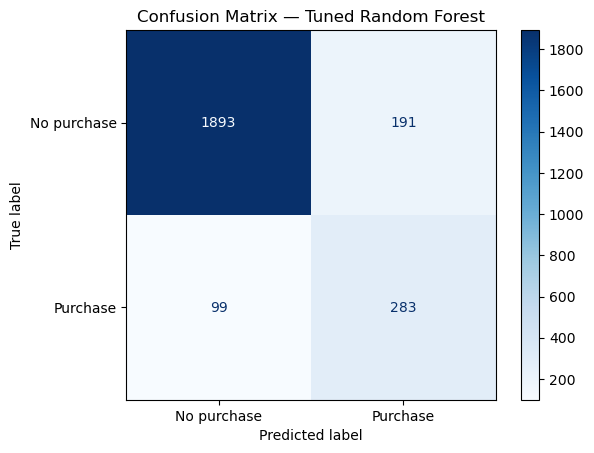

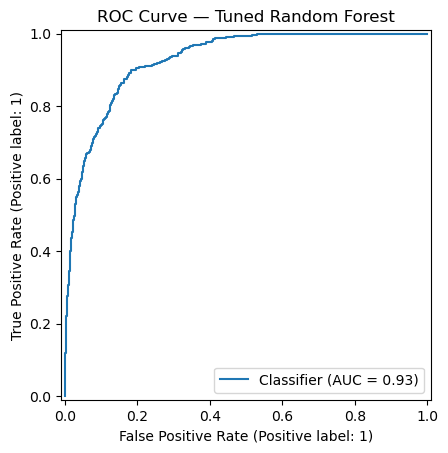

In [13]:
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["No purchase", "Purchase"], cmap="Blues"
)
plt.title("Confusion Matrix — Tuned Random Forest")
plt.show()

RocCurveDisplay.from_predictions(y_test, test_prob)
plt.title("ROC Curve — Tuned Random Forest")
plt.show()

## 9. Error analysis

Inspect false positives and false negatives. A false positive means the model predicts a purchase but none occurs; a false negative means it misses a session that actually purchases.

In [14]:
error_analysis = X_test.copy()
error_analysis["Actual"] = y_test.values
error_analysis["Predicted"] = test_pred
error_analysis["Purchase_Probability"] = test_prob
error_analysis["Error_Type"] = np.select(
    [
        (error_analysis["Actual"] == 0) & (error_analysis["Predicted"] == 1),
        (error_analysis["Actual"] == 1) & (error_analysis["Predicted"] == 0)
    ],
    ["False Positive", "False Negative"],
    default="Correct"
)
display(error_analysis[error_analysis["Error_Type"] != "Correct"].head(20))
display(error_analysis["Error_Type"].value_counts())

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Actual,Predicted,Purchase_Probability,Error_Type
11507,3,67.750000,0,0.00,2,19.250000,0.040000,0.053333,0.000000,0.0,...,1,1,3,20,New_Visitor,False,1,0,0.259793,False Negative
10682,15,404.766667,4,240.50,120,4173.131061,0.006716,0.027928,9.269828,0.0,...,2,2,3,2,Returning_Visitor,True,0,1,0.602729,False Positive
6922,0,0.000000,0,0.00,15,956.333333,0.013333,0.046667,20.139076,0.0,...,2,2,3,1,Returning_Visitor,False,0,1,0.849435,False Positive
7322,1,32.200000,0,0.00,17,876.428571,0.000000,0.004063,0.000000,0.0,...,3,2,1,3,Returning_Visitor,False,1,0,0.149449,False Negative
12027,9,795.208333,0,0.00,118,4947.358038,0.001138,0.011201,2.270358,0.0,...,3,2,5,2,Returning_Visitor,False,0,1,0.671213,False Positive
11798,0,0.000000,0,0.00,6,81.750000,0.000000,0.066667,0.000000,0.0,...,2,2,1,3,Returning_Visitor,False,1,0,0.126745,False Negative
10044,0,0.000000,2,207.25,114,3788.800000,0.003478,0.010435,1.795451,0.0,...,2,2,3,2,Returning_Visitor,True,0,1,0.610720,False Positive
4450,3,46.000000,3,53.50,15,270.571429,0.042105,0.069737,12.152105,0.0,...,3,2,4,5,Returning_Visitor,True,0,1,0.502988,False Positive
9486,4,69.833333,0,0.00,133,4885.049069,0.002963,0.008689,15.955388,0.0,...,1,2,1,2,Returning_Visitor,True,0,1,0.913609,False Positive
4433,10,62.500000,1,93.00,28,724.333333,0.000000,0.023232,14.737091,0.2,...,2,2,4,5,New_Visitor,False,0,1,0.644217,False Positive


Error_Type
Correct           2176
False Positive     191
False Negative      99
Name: count, dtype: int64

## 10. Save the trained pipeline for the web app

In [15]:
os.makedirs("artifacts", exist_ok=True)
joblib.dump(best_model, "artifacts/purchase_intention_pipeline.joblib")
print("Saved: artifacts/purchase_intention_pipeline.joblib")

Saved: artifacts/purchase_intention_pipeline.joblib


## 11. Business recommendation and limitations
Business Recommendations
1. Use purchase-intent predictions to identify visitors who may need additional support before completing a purchase.
2. Offer helpful product information or live chat assistance to visitors with moderate purchase likelihood.
3. Consider targeted promotions for selected visitors, subject to business rules and campaign budgets.
4. Prioritize improving product pages and reducing barriers during the shopping journey.
5. Evaluate campaign performance using actual conversion rates before adopting prediction-based actions.
Limitations
1. The model is trained on historical session data and may not represent future customer behavior.
2. The dataset contains imbalanced target classes, with only 15.47% of sessions resulting in purchases.
3. Model predictions represent probabilities, not guaranteed purchasing decisions.
4. The model does not establish causal relationships between visitor behavior and purchases.
5. Business action thresholds require validation through real campaign experiments.